# Very Simple Regression

## 1) IMPORT LIBRARIES AND DATASETS

In [4]:
# Import Pkgs
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
from google.colab import files
files.upload()

Saving gold-monthly-processed.csv to gold-monthly-processed.csv


{'gold-monthly-processed.csv': b'Date,Price\n1833-01-01,18.930\n1833-02-01,18.930\n1833-03-01,18.930\n1833-04-01,18.930\n1833-05-01,18.930\n1833-06-01,18.930\n1833-07-01,18.930\n1833-08-01,18.930\n1833-09-01,18.930\n1833-10-01,18.930\n1833-11-01,18.930\n1833-12-01,18.930\n1834-01-01,18.930\n1834-02-01,18.930\n1834-03-01,18.930\n1834-04-01,18.930\n1834-05-01,18.930\n1834-06-01,18.930\n1834-07-01,18.930\n1834-08-01,18.930\n1834-09-01,18.930\n1834-10-01,18.930\n1834-11-01,18.930\n1834-12-01,18.930\n1835-01-01,18.930\n1835-02-01,18.930\n1835-03-01,18.930\n1835-04-01,18.930\n1835-05-01,18.930\n1835-06-01,18.930\n1835-07-01,18.930\n1835-08-01,18.930\n1835-09-01,18.930\n1835-10-01,18.930\n1835-11-01,18.930\n1835-12-01,18.930\n1836-01-01,18.930\n1836-02-01,18.930\n1836-03-01,18.930\n1836-04-01,18.930\n1836-05-01,18.930\n1836-06-01,18.930\n1836-07-01,18.930\n1836-08-01,18.930\n1836-09-01,18.930\n1836-10-01,18.930\n1836-11-01,18.930\n1836-12-01,18.930\n1837-01-01,18.930\n1837-02-01,18.930\n1837-

In [6]:
gold_df = pd.read_csv('gold-monthly-processed.csv', sep=',')
gold_df.columns = gold_df.columns.str.lower()
# ubah kolom date menjadi datetime
gold_df['date'] = pd.to_datetime(gold_df['date'])

# ambil data dari tahun 2020 sampai 2026
gold_df = gold_df[
    (gold_df['date'].dt.year >= 2022) &
    (gold_df['date'].dt.year <= 2026)
]

gold_df

,date,price
2268,2022-01-01,1816.00
2269,2022-02-01,1856.00
2270,2022-03-01,1948.00
2271,2022-04-01,1937.00
2272,2022-05-01,1849.00
2273,2022-06-01,1837.00
2274,2022-07-01,1733.00
2275,2022-08-01,1765.00
2276,2022-09-01,1681.00
2277,2022-10-01,1664.00


In [7]:
gold_df.head(10)

,date,price
2268,2022-01-01,1816.0
2269,2022-02-01,1856.0
2270,2022-03-01,1948.0
2271,2022-04-01,1937.0
2272,2022-05-01,1849.0
2273,2022-06-01,1837.0
2274,2022-07-01,1733.0
2275,2022-08-01,1765.0
2276,2022-09-01,1681.0
2277,2022-10-01,1664.0


In [8]:
gold_df.tail(8)

,date,price
2316,2026-01-01,4753.0
2317,2026-02-01,5020.0
2318,2026-03-01,4856.0
2319,2026-04-01,4721.0
2320,2026-05-01,4587.0
2321,2026-06-01,4228.0
2322,2026-07-01,4073.0
2323,2026-08-01,4411.0


In [9]:
# Check the minimun gold price
gold_df['price'].min()

1664.0

## 2) Exploratory Data Analysis (EDA) and Visualizations

In [10]:
# check if there are any Null values
gold_df.isnull().sum()

,0
date,0
price,0


In [11]:
# Check the dataframe info
gold_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 56 entries, 2268 to 2323
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    56 non-null     datetime64[ns]
 1   price   56 non-null     float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 1.3 KB


In [12]:
# Statistical summary of the dataframe
gold_df.describe()

,date,price
count,56,56.000000
mean,2024-04-16 04:17:08.571428608,2705.720179
min,2022-01-01 00:00:00,1664.000000
25%,2023-02-22 00:00:00,1916.000000
50%,2024-04-16 00:00:00,2328.500000
75%,2025-06-08 12:00:00,3343.250000
max,2026-08-01 00:00:00,5020.000000
std,NaN,1016.535400


In [13]:
# tahun yang memiliki harga tertinggi
max = gold_df[gold_df['date'] == gold_df['date'].max()]

In [14]:
max

,date,price
2323,2026-08-01,4411.0


In [15]:
# tahun yang memiliki harga terendah
min = gold_df[gold_df['price'] == gold_df['price'].min()]

In [16]:
min

,date,price
2277,2022-10-01,1664.0


<Axes: >

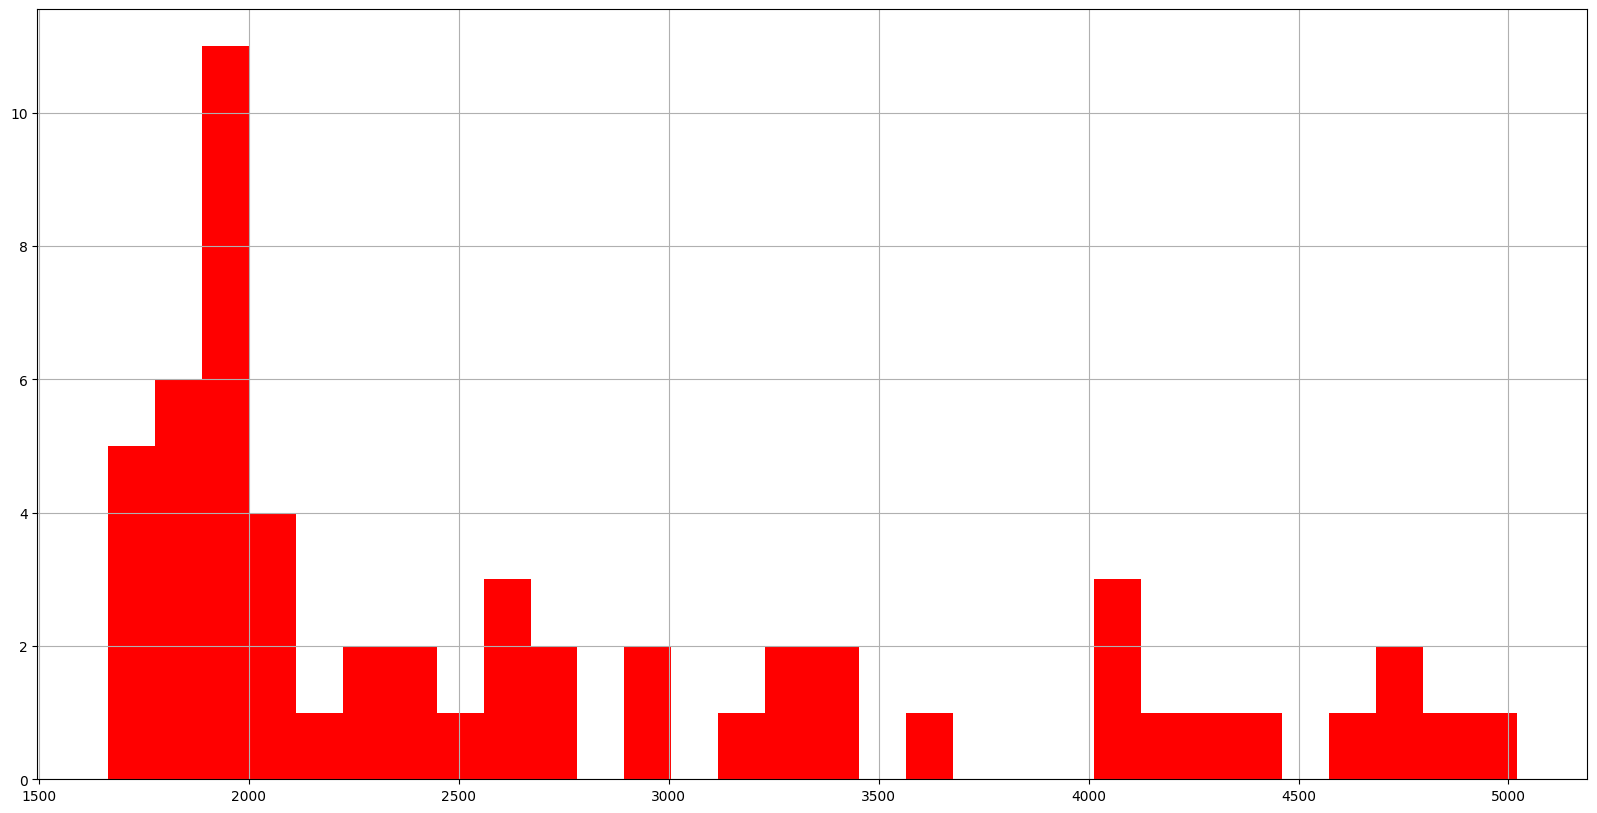

In [17]:
# Histogram Plotting (Data Distribution)
gold_df["price"].hist(bins = 30, figsize = (20,10), color = 'r')

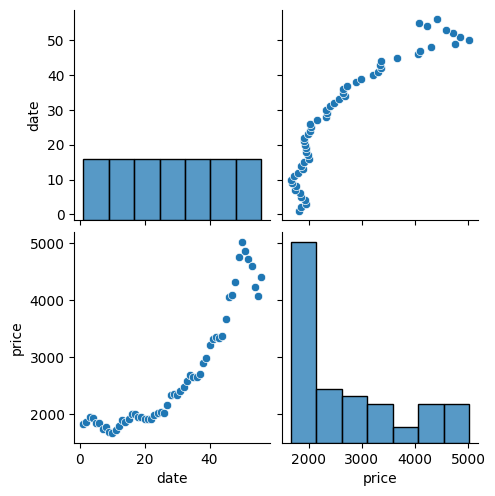

In [18]:
# Plot Pairplot (Variables Relationship)
gold_df['date'] = range(1, len(gold_df) + 1)
sns.pairplot(gold_df[['date', 'price']])

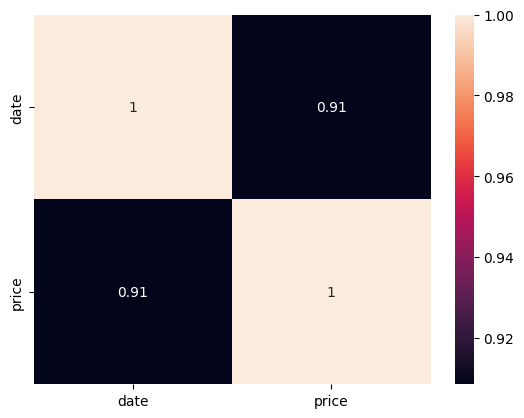

In [19]:
# Correlation Matrix
corr_matrix = gold_df[['date', 'price']].corr()
sns.heatmap(corr_matrix, annot = True)
plt.show()

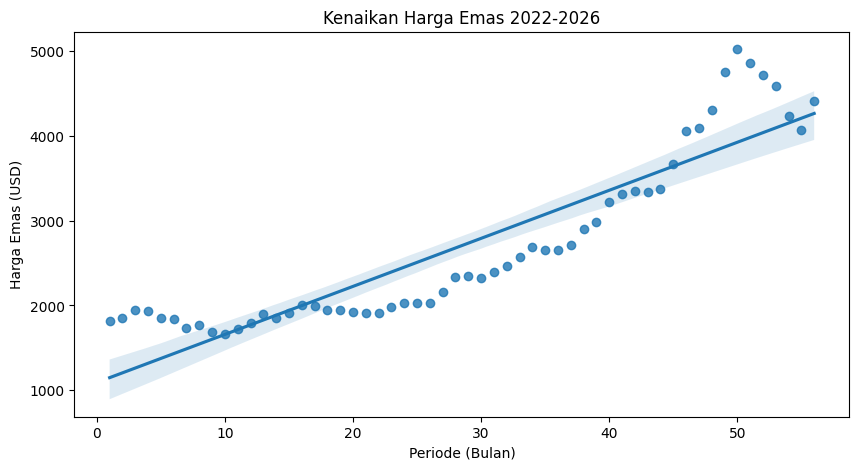

In [20]:
# Regression Plot with Seaborn (straight line fit between "date" and "price")
plt.figure(figsize=(10, 5))
sns.regplot(x='date',y='price',data=gold_df)
plt.xlabel('Periode (Bulan)')
plt.ylabel('Harga Emas (USD)')
plt.title('Kenaikan Harga Emas 2022-2026')
plt.show()

## 3) TRAINING AND TESTING DATA

In [21]:
X = gold_df[['date']]
y = gold_df[['price']]

In [22]:
X

,date
2268,1
2269,2
2270,3
2271,4
2272,5
2273,6
2274,7
2275,8
2276,9
2277,10


In [23]:
y

,price
2268,1816.00
2269,1856.00
2270,1948.00
2271,1937.00
2272,1849.00
2273,1837.00
2274,1733.00
2275,1765.00
2276,1681.00
2277,1664.00


In [24]:
X.shape

(56, 1)

In [25]:
y.shape

(56, 1)

In [26]:
X = np.array(X)
y = np.array(y)

In [27]:
X.shape

(56, 1)

In [28]:
# split the data into test and train sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state=72)

In [29]:
X_train.shape

(42, 1)

In [30]:
X_test.shape

(14, 1)

In [31]:
print(X)

[[ 1]
 [ 2]
 [ 3]
 [ 4]
 [ 5]
 [ 6]
 [ 7]
 [ 8]
 [ 9]
 [10]
 [11]
 [12]
 [13]
 [14]
 [15]
 [16]
 [17]
 [18]
 [19]
 [20]
 [21]
 [22]
 [23]
 [24]
 [25]
 [26]
 [27]
 [28]
 [29]
 [30]
 [31]
 [32]
 [33]
 [34]
 [35]
 [36]
 [37]
 [38]
 [39]
 [40]
 [41]
 [42]
 [43]
 [44]
 [45]
 [46]
 [47]
 [48]
 [49]
 [50]
 [51]
 [52]
 [53]
 [54]
 [55]
 [56]]


In [32]:
X_train

array([[19],
       [24],
       [56],
       [15],
       [51],
       [37],
       [34],
       [55],
       [44],
       [43],
       [36],
       [50],
       [18],
       [23],
       [39],
       [49],
       [26],
       [ 4],
       [ 3],
       [32],
       [33],
       [54],
       [ 1],
       [48],
       [ 2],
       [29],
       [ 9],
       [17],
       [41],
       [13],
       [22],
       [30],
       [ 8],
       [27],
       [16],
       [ 6],
       [31],
       [38],
       [11],
       [47],
       [20],
       [25]])

## 4) Train a Linear Regression Model

In [33]:
# using linear regression model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

lr = LinearRegression(fit_intercept = True) # Fit intercept is the "b" parameter (y = b + mx)
lr.fit(X_train, y_train)

LinearRegression()

In [34]:
# Checking the accuracy
y_pred = lr.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE  :", mse)
print("RMSE :", rmse)
print("MAE  :", mae)
print("R²   :", r2)

MSE  : 121150.22801894012
RMSE : 348.0664132302054
MAE  : 269.4685277500109
R²   : 0.8936750426892957


In [35]:
print('Linear Model Coefficient (m): ', lr.coef_)
print('Linear Model Coefficient (b): ', lr.intercept_)

Linear Model Coefficient (m):  [[55.15306734]]
Linear Model Coefficient (b):  [1112.0586222]


## 5) EVALUATE TRAINED MODEL PERFORMANCE

In [36]:
y_pred

array([[1773.8954303 ],
       [1884.20156499],
       [1387.82395891],
       [4035.17119132],
       [1663.58929562],
       [3428.48745056],
       [2656.34450778],
       [1498.1300936 ],
       [3318.18131588],
       [3042.41597917],
       [3649.09971993],
       [2270.27303638],
       [3593.94665259],
       [3980.01812398]])

Text(0.5, 1.0, 'Price vs. Periode')

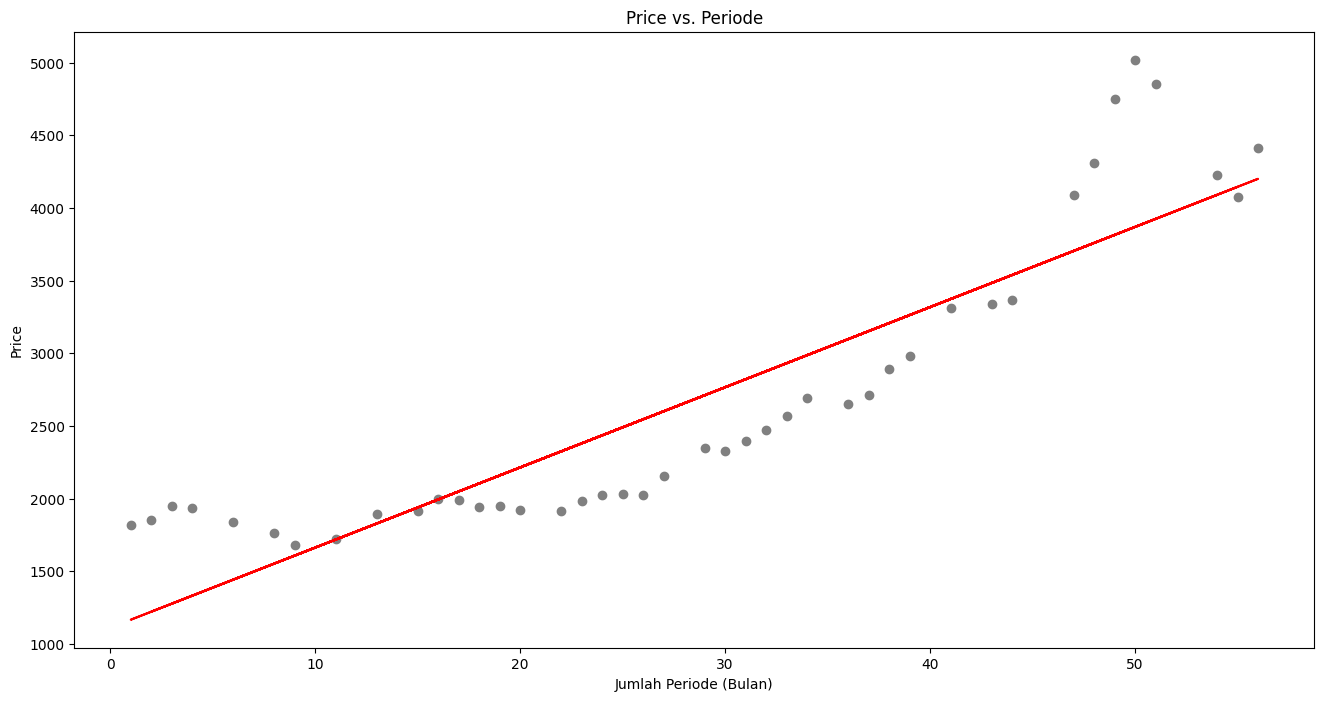

In [37]:
# Plotting the TRAIN DATA
plt.figure(figsize=(16,8))
plt.scatter(X_train, y_train, color = 'gray')
plt.plot(X_train, lr.predict(X_train), color = 'red')
plt.ylabel('Price')
plt.xlabel('Jumlah Periode (Bulan)')
plt.title('Price vs. Periode')

## 6) Making Predictions
 - Use the trained model to obtain the salary corresponding to eployees who have 5 years of experience

In [38]:
new_value = [[56.0]] # data untuk diprediksi
new_prediction = lr.predict(new_value)
new_prediction

array([[4200.63039335]])

## 7) Save the Model

In [39]:
import joblib

model_file = open("linear_regression_emas.pkl","wb")
joblib.dump(lr,model_file)
model_file.close()

In [40]:
files.download('linear_regression_emas.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>